In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
# setting up a cool matplotlib style!!

plt.style.use('fivethirtyeight')

In [62]:
df = pd.read_csv('../data/cleaned_property_price.csv')
df.sample(5)

,property_type,location,area_sqft,bedrooms,bathrooms,age_years,floor,total_floors,parking,furnishing,distance_to_metro_km,nearby_schools,monthly_maintenance_inr,has_gym,has_security,price_lakhs
876,apartment,pitampura,802.0,1,2.0,12.0,3,13,no,semi-furnished,0.86,3,1884.0,yes,yes,98.37
1104,apartment,rohini,1203.0,3,4.0,14.0,1,14,no,unfurnished,0.91,4,2726.0,no,no,94.88
1786,apartment,pitampura,1640.0,5,5.0,4.0,13,17,yes,unfurnished,1.08,1,5188.0,no,yes,147.06
59,apartment,rohini,2133.0,5,5.0,8.0,4,7,yes,unfurnished,1.24,0,5244.0,no,yes,151.39
1402,independent house,gurugram,991.0,2,1.0,7.0,21,21,yes,semi-furnished,4.08,3,2207.0,no,yes,116.66


In [63]:
# univariate analysis!!

# 1. Numerical cols
# 2. Categorical cols

In [64]:
# numerical cols

In [73]:
num_cols = df.select_dtypes(include='number').columns.tolist()[:-1]
num_cols

['area_sqft',
 'bedrooms',
 'bathrooms',
 'age_years',
 'floor',
 'total_floors',
 'distance_to_metro_km',
 'nearby_schools',
 'monthly_maintenance_inr']

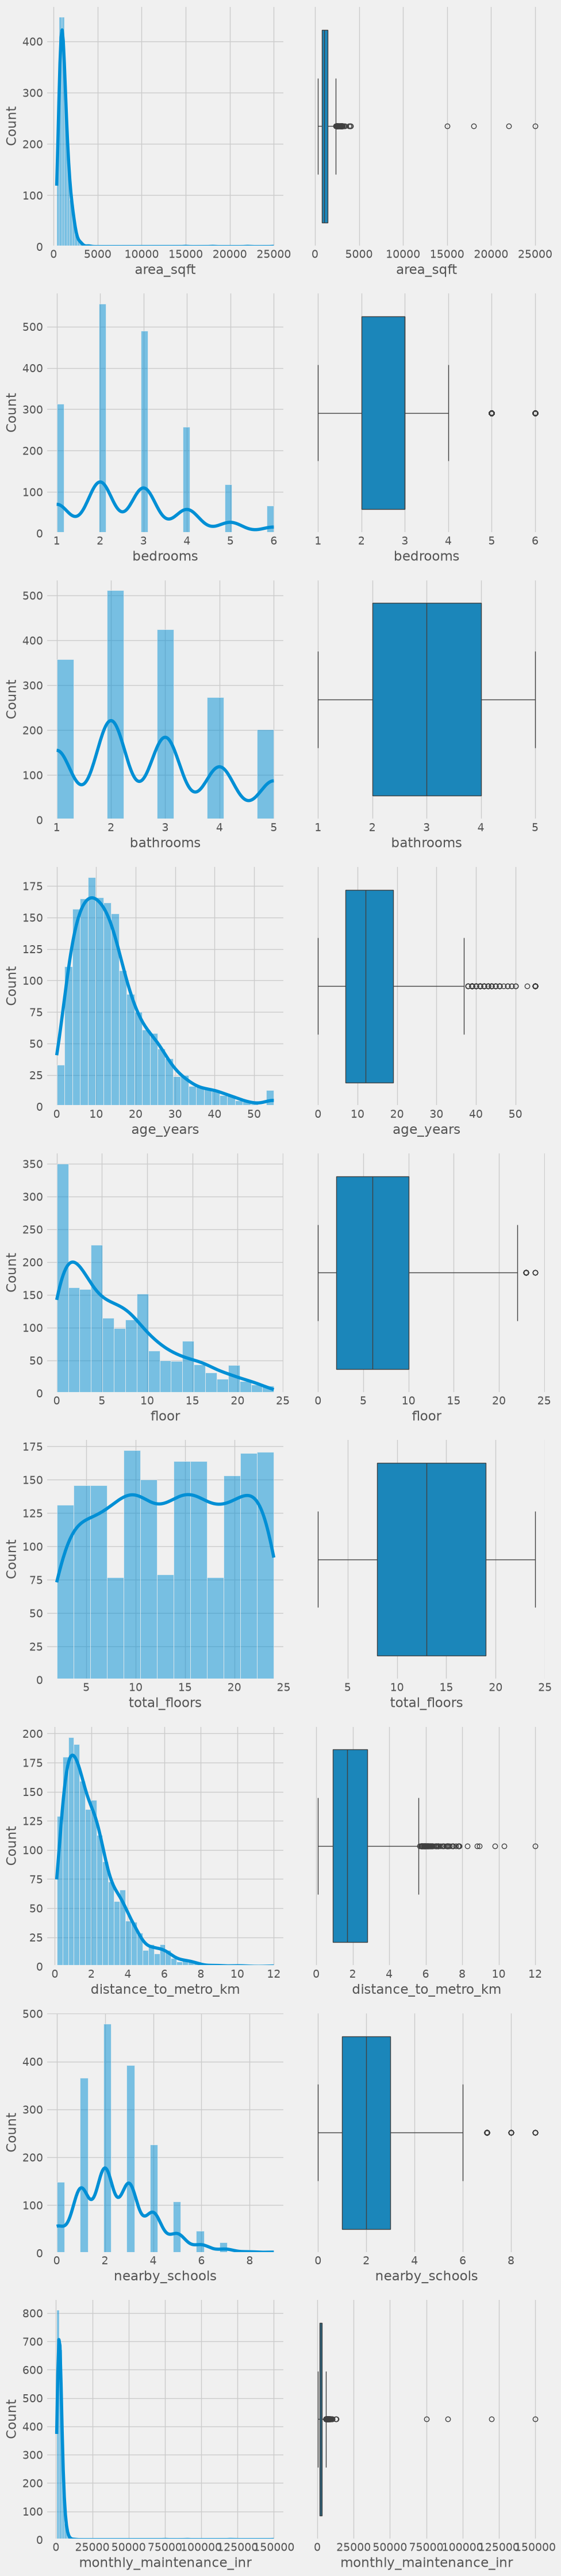

In [74]:
fig, axes = plt.subplots(len(num_cols), 2, figsize=(10, 5 * len(num_cols)))

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i, 0])
    sns.boxplot(data=df, x=col, ax=axes[i, 1])

plt.tight_layout()
plt.show()

In [67]:
# categorical cols

In [68]:
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
cat_cols

['property_type',
 'location',
 'parking',
 'furnishing',
 'has_gym',
 'has_security']

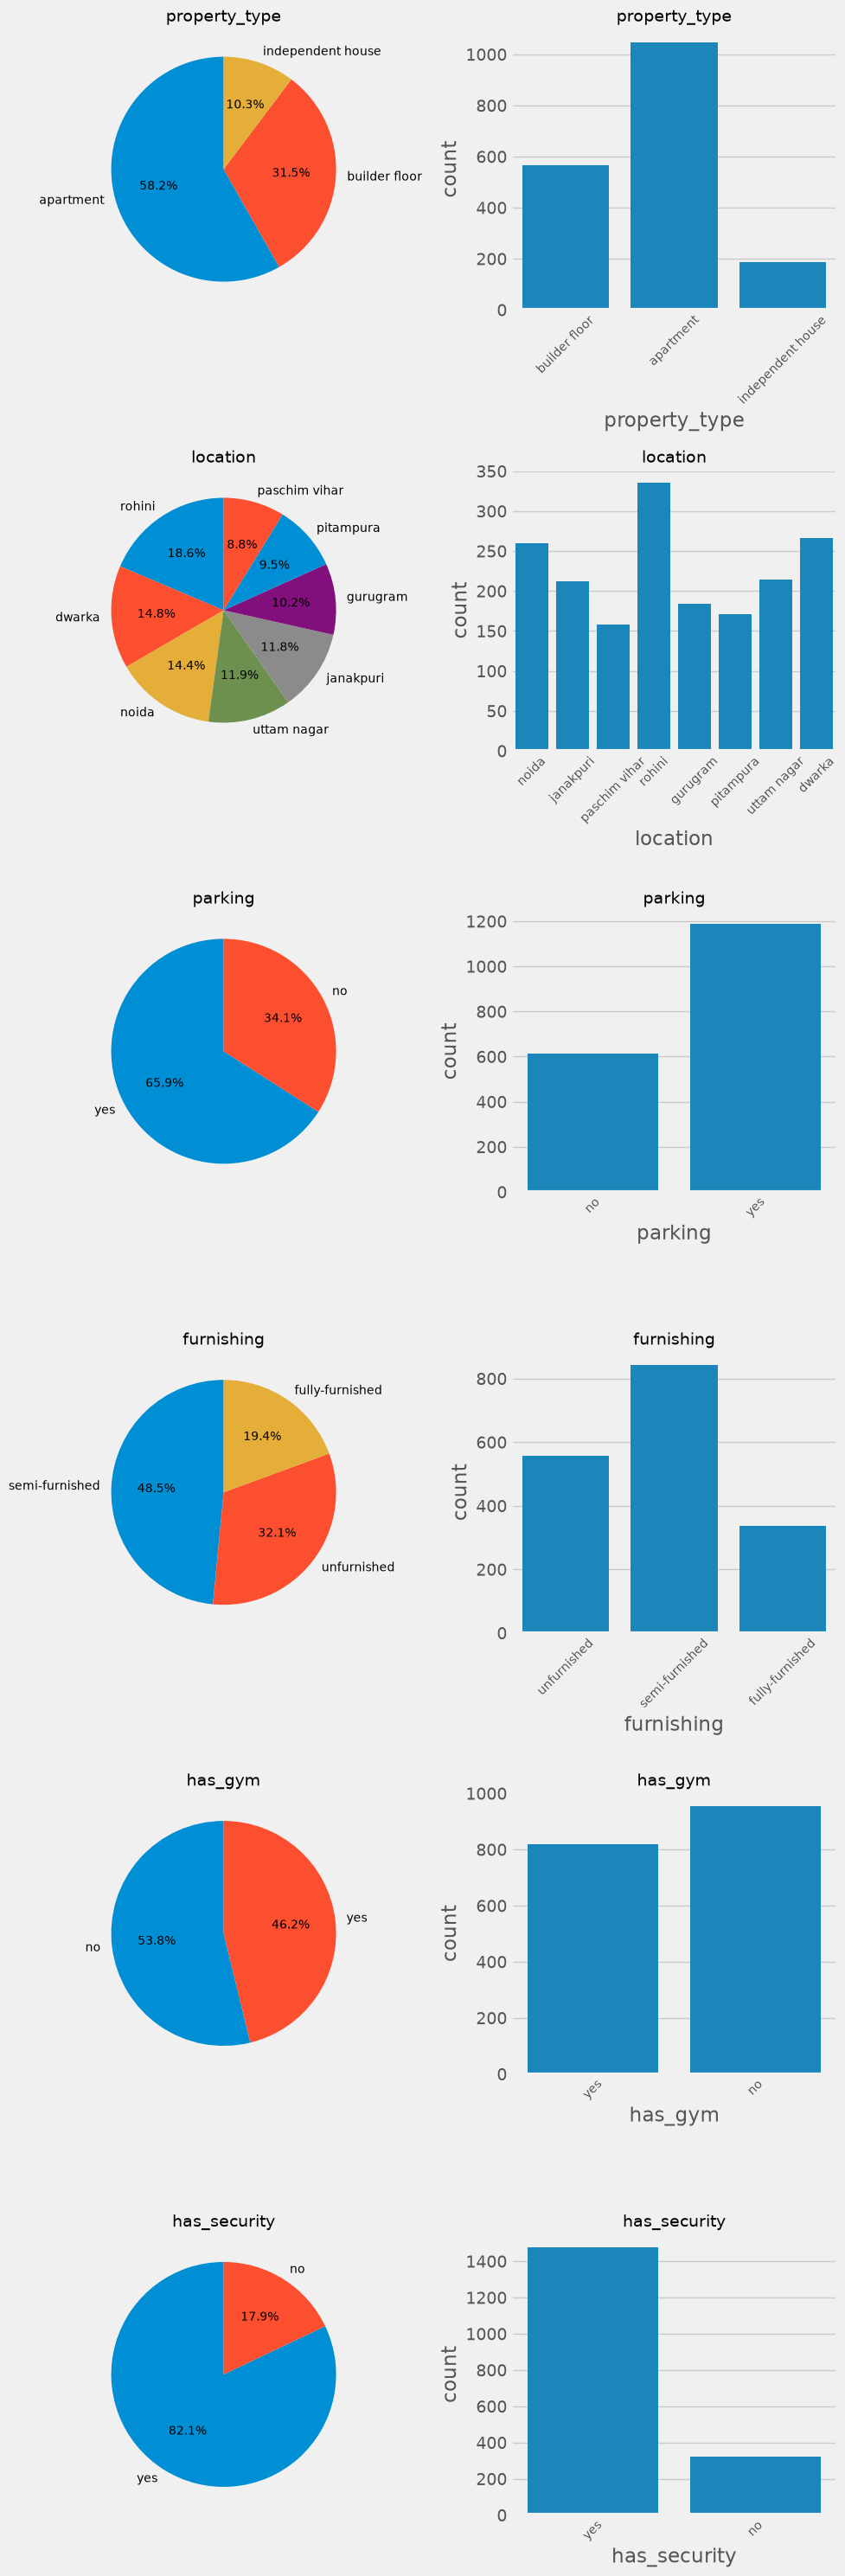

In [76]:
fig, axes = plt.subplots(len(cat_cols), 2, figsize=(10, 5 * len(cat_cols)))

for i, col in enumerate(cat_cols):
    value_cnt = df[col].value_counts()

    axes[i, 0].pie(
        value_cnt,
        labels=value_cnt.index,
        autopct='%.1f%%',
        startangle=90,
        textprops={'fontsize': 10}
    )
    axes[i, 0].set_title(col, fontsize=14)

    sns.countplot(data=df, x=col, ax=axes[i, 1])
    axes[i, 1].set_title(col, fontsize=14)
    axes[i, 1].tick_params(axis='x', labelrotation=45, labelsize=10)

plt.tight_layout()
plt.show()

In [70]:
# bivariate analysis

In [72]:
# numerical cols with target 
# scatterplot and regplot

# categorical cols with target
# boxplot and barplot

In [94]:
target_col = 'price_lakhs'

In [75]:
# 1. numerical cols with target

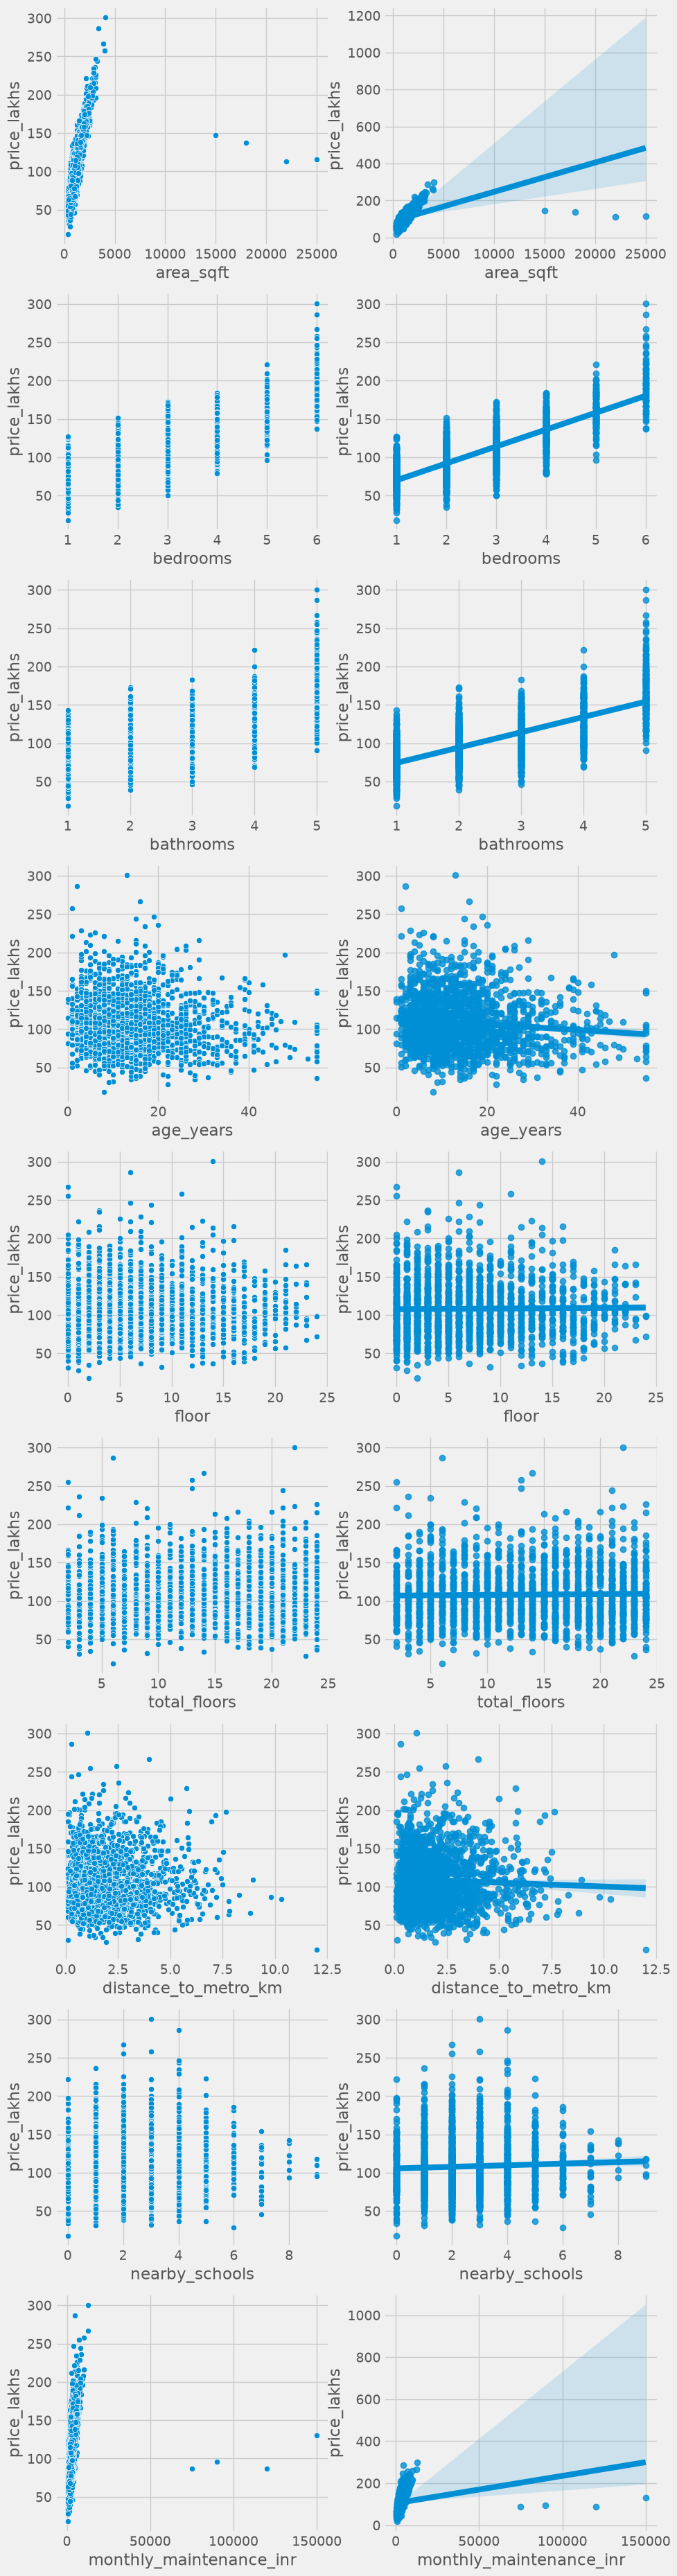

In [96]:
fig, axes = plt.subplots(len(num_cols), 2, figsize=(10, 5*len(num_cols)))

for i, col in enumerate(num_cols):
    sns.scatterplot(data=df, x=col, y=target_col, ax=axes[i,0])
    sns.regplot(data=df, x=col, y=target_col, ax=axes[i, 1])

In [97]:
# 2. categorical cols with target

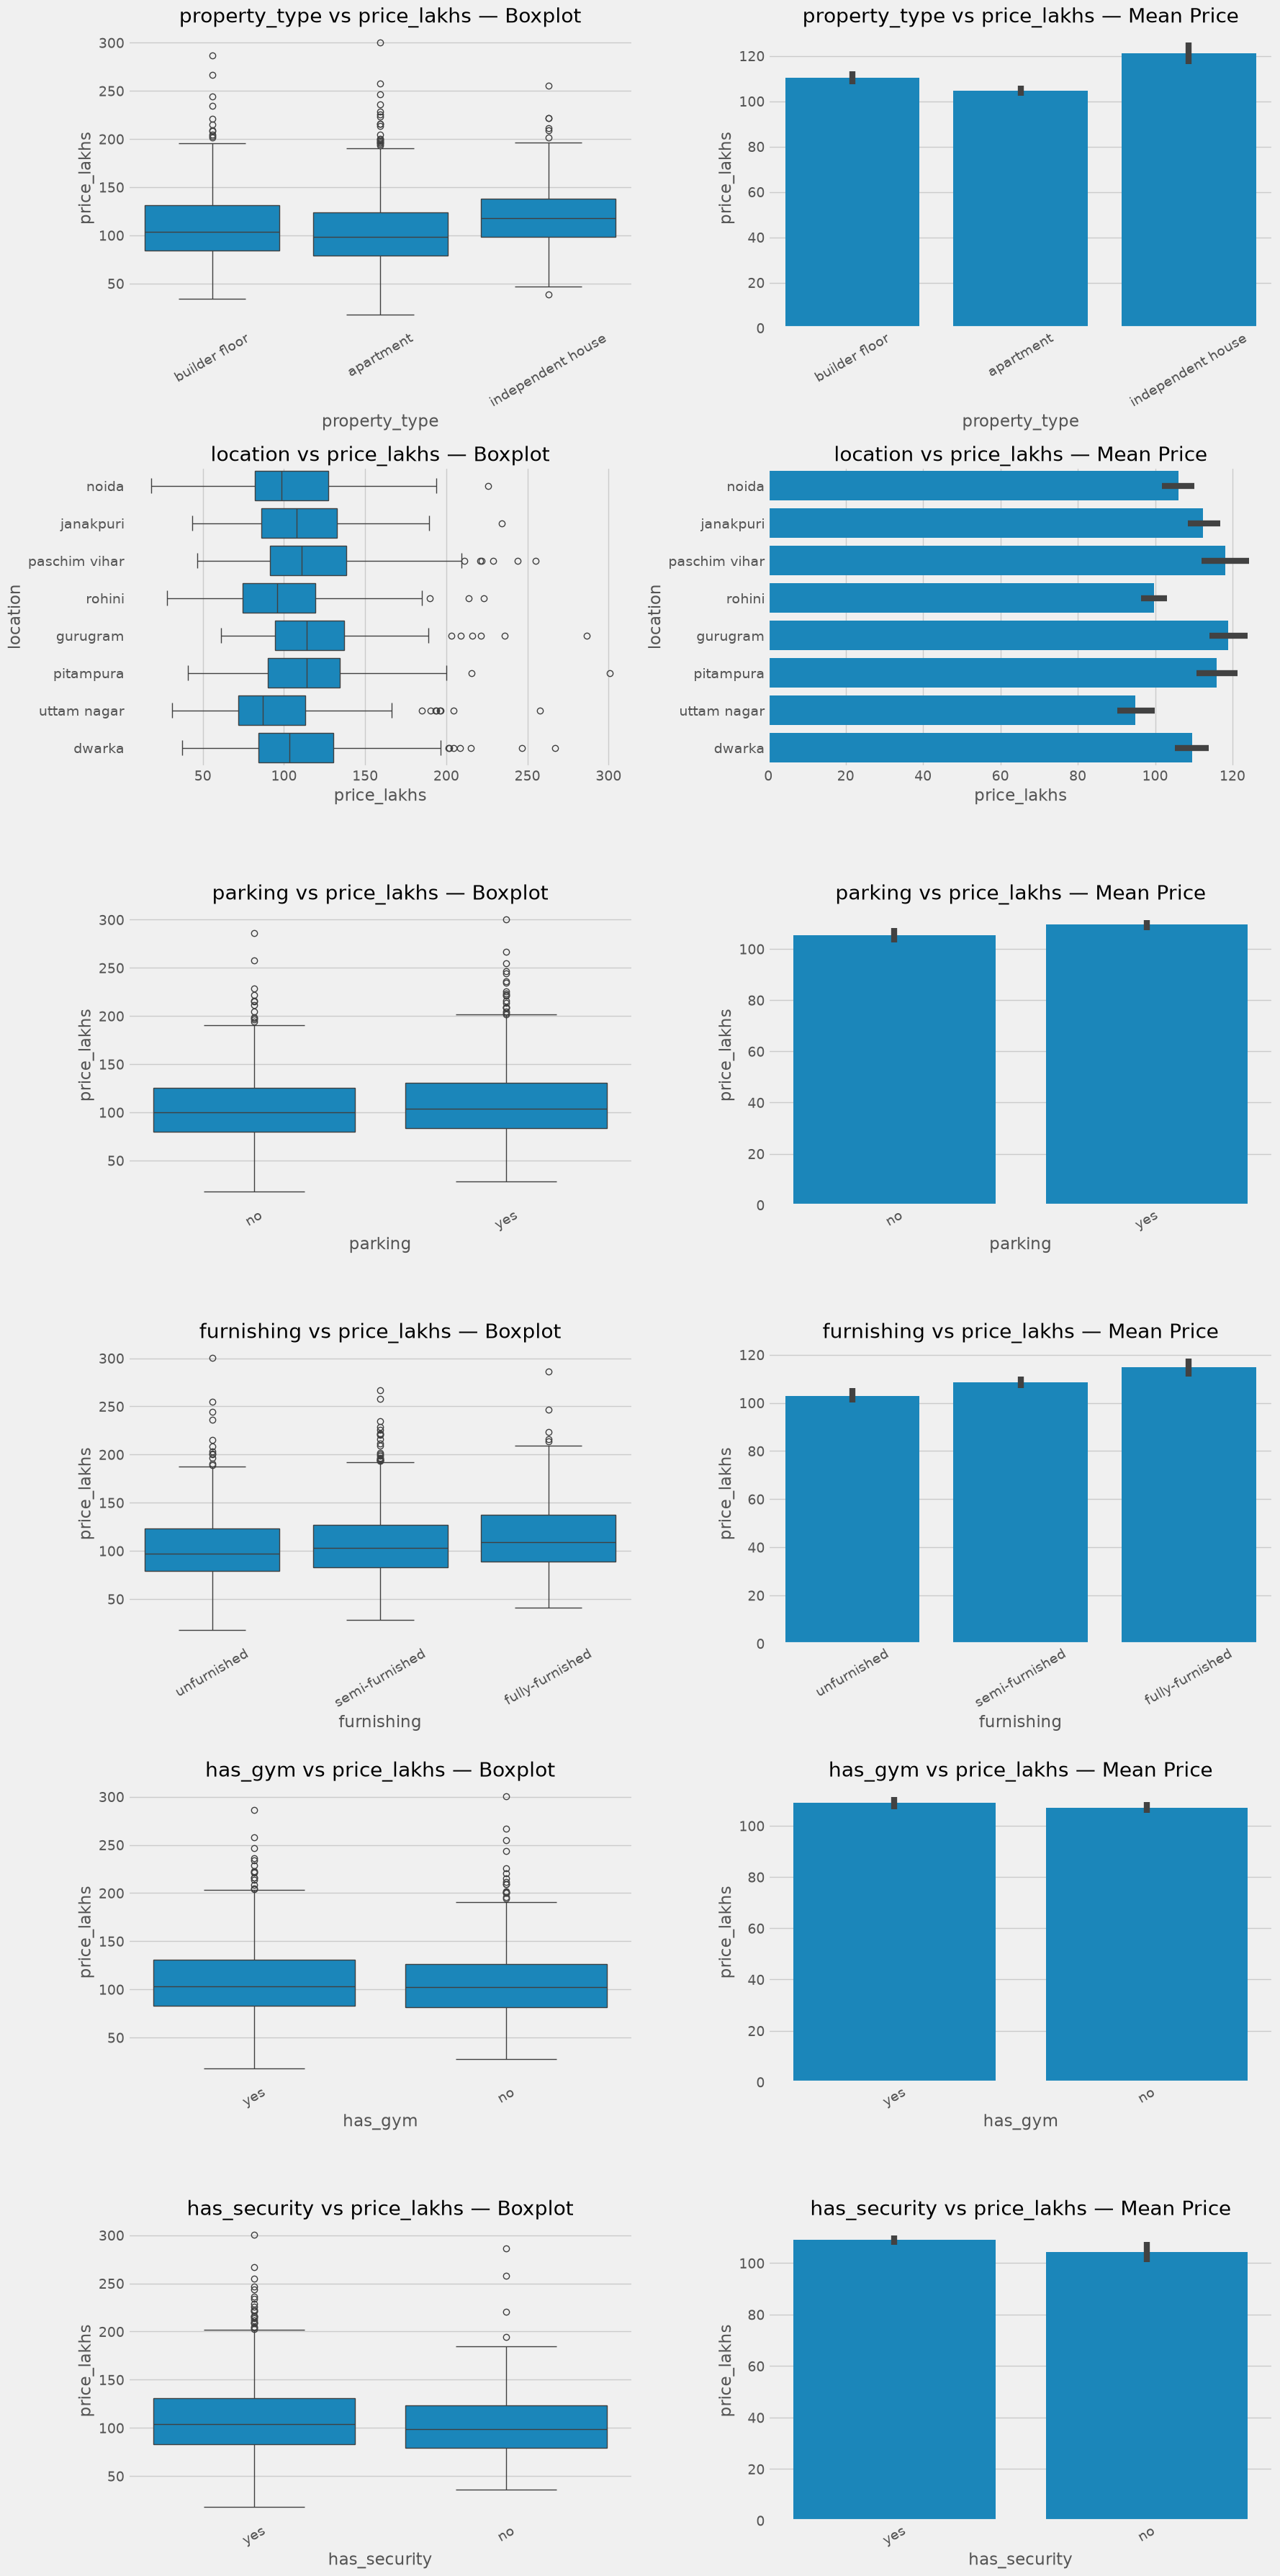

In [101]:
fig, axes = plt.subplots(
    len(cat_cols), 2,
    figsize=(18, 6 * len(cat_cols))
)

for i, col in enumerate(cat_cols):
    if col == 'location':
        sns.boxplot(data=df, x=target_col, y=col, ax=axes[i, 0])
        sns.barplot(data=df, x=target_col, y=col, ax=axes[i, 1])
    else:
        sns.boxplot(data=df, x=col, y=target_col, ax=axes[i, 0])
        sns.barplot(data=df, x=col, y=target_col, ax=axes[i, 1])
        axes[i, 0].tick_params(axis='x', rotation=30)
        axes[i, 1].tick_params(axis='x', rotation=30)

    axes[i, 0].set_title(f'{col} vs {target_col} — Boxplot')
    axes[i, 1].set_title(f'{col} vs {target_col} — Mean Price')

plt.tight_layout()
plt.show()

In [102]:
# multivariate analysis

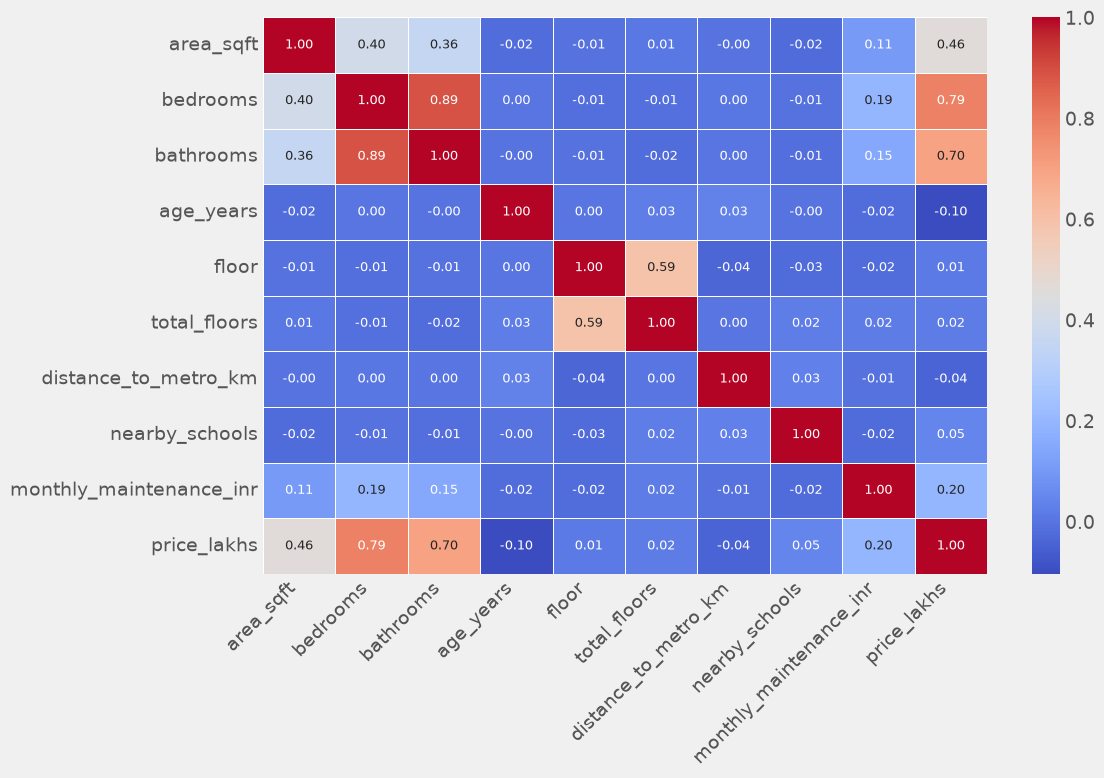

In [106]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    annot_kws={"size": 9}
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [107]:
# suspicious outliers!

In [108]:
df[df['area_sqft'] > 10000]

,property_type,location,area_sqft,bedrooms,bathrooms,age_years,floor,total_floors,parking,furnishing,distance_to_metro_km,nearby_schools,monthly_maintenance_inr,has_gym,has_security,price_lakhs
601,builder floor,paschim vihar,15000.0,3,3.0,26.0,6,20,no,fully-furnished,1.80,2,4222.0,yes,yes,147.03
791,builder floor,pitampura,18000.0,3,3.0,7.0,6,12,no,semi-furnished,0.84,1,2968.0,yes,yes,137.21
1001,apartment,janakpuri,22000.0,2,3.0,3.0,9,19,yes,fully-furnished,4.23,4,2630.0,no,yes,113.27
1699,builder floor,paschim vihar,25000.0,1,1.0,6.0,1,4,yes,unfurnished,0.60,1,1747.0,no,yes,115.75
